In [1]:
import torch
import torch.nn as nn
import numpy as np

# dynamic method research

In [4]:
from sinar.models import BaseClassifierModel
model = BaseClassifierModel.load("./models/svm.pkl")
model

/home/versa/project/sinar-backend/.venv/lib/python3.12/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator SVC from version 1.3.2 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


SVC(C=100, gamma=0.01)

In [3]:
matrix = np.random.rand(1, 30, 64).astype(np.float32)
model.predict(matrix)

array([0], dtype=int32)

In [ ]:
from sinar.utils import fill_square

x = np.random.rand(1, 30, 64).astype(np.float32)
if len(x.shape) == 3:
    x = np.array([fill_square(xi) for xi in x])
else:
    x = fill_square(x)
x.shape

(1, 30, 30)

In [5]:
torch.load("best_model.pth").keys()

odict_keys(['conv1.0.weight', 'conv1.0.bias', 'conv2.0.weight', 'conv2.0.bias', 'conv3.0.weight', 'conv3.0.bias', 'fc.weight', 'fc.bias'])

In [19]:
SEED       = 1337
EPOCHS     = 12
LR         = 6e-4
WEIGHT_DEC = 5e-7
DROPOUT    = 0.40
N_F1       = 32
N_F2       = 64
N_F3       = 96 

class PaperStyleCNN(nn.Module):
    def __init__(self, nf1=N_F1, nf2=N_F2, nf3=N_F3, dropout=DROPOUT):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=(1,2), stride=(1,2), padding=(0,0)),
            nn.ReLU(inplace=True)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(2,1), stride=(2,1), padding=(0,0)),
            nn.ReLU(inplace=True),
            # nn.Dropout(dropout)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 96, kernel_size=(5,5), stride=1, padding=2),
            nn.ReLU(inplace=True)
        )
        self.gap = nn.AdaptiveAvgPool2d((1,1))
        # self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(96, 2)

    def forward(self, x):
        h = self.conv1(x)
        h = self.conv2(h)
        h = self.conv3(h)
        h = self.gap(h).flatten(1)
        # h = self.dropout(h)
        return self.fc(h)

@torch.no_grad()
def evaluate(loader, model, threshold=None):
    model.eval()
    total, hit = 0, 0
    ys, ps = [], []
    for batch in loader:
        X = batch["x"].unsqueeze(0).to(device)  # bs=1
        Y = batch["y"].view(1).to(device)
        logits = model(X)
        if threshold is None:
            pred = logits.argmax(dim=1)
        else:
            p1 = logits.softmax(dim=1)[:,1]
            pred = (p1 >= threshold).long()
        hit += (pred == Y).sum().item()
        total += 1
        ys.append(int(Y.item()))
        ps.append(int(pred.item()))
    acc = hit/total if total else 0.0
    return acc, ys, ps

In [9]:
{k: v.shape for k,v in torch.load("best_model.pth").items()}

{'conv1.0.weight': torch.Size([32, 1, 1, 2]),
 'conv1.0.bias': torch.Size([32]),
 'conv2.0.weight': torch.Size([64, 32, 2, 1]),
 'conv2.0.bias': torch.Size([64]),
 'conv3.0.weight': torch.Size([96, 64, 5, 5]),
 'conv3.0.bias': torch.Size([96]),
 'fc.weight': torch.Size([2, 96]),
 'fc.bias': torch.Size([2])}

In [20]:
model = PaperStyleCNN()
model.load_state_dict(torch.load("best_model.pth"))
model

PaperStyleCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(1, 2), stride=(1, 2))
    (1): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(2, 1), stride=(2, 1))
    (1): ReLU(inplace=True)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 96, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU(inplace=True)
  )
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=96, out_features=2, bias=True)
)

In [1]:
from sinar.motas import TorchMotas

motas = TorchMotas("best_model.pth", use_flatten=False, live_stream=False)
motas

[INFO @ motas] - [MainProcess / MainThread] - Loading PyTorch model best_model.pth
[INFO @ motas] - [MainProcess / MainThread] - Motion Analysis model loaded with type <TorchMotas>


TorchMotas(
  (conv1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(1, 2), stride=(1, 2))
    (1): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(2, 1), stride=(2, 1))
    (1): ReLU(inplace=True)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 96, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU(inplace=True)
  )
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=96, out_features=2, bias=True)
)

In [2]:
motas.ready()

AttributeError: 'TorchMotas' object has no attribute 'centroids'

In [4]:
torch.device("intel:gpu")

RuntimeError: Invalid device string: 'intel:gpu'

In [3]:
import sinar.logger
from sinar import SINAR, stream
import os
import cv2
import time
import numpy as np
import pandas as pd
from sinar.utils import VideoInfo
import random

sinar.logger.set_level("DEBUG")

sinar = SINAR("models/y11m_openvino_model/", "best_model.pth", device="intel:gpu", probability_threshold=0.6)

reports = []
files = os.listdir("vid") # directory video

for file in files:
    if not file.endswith(".mp4"):
        continue
    print(f"Processing {file} ...")
    vi = VideoInfo.from_video_path(f"vid/{file}")
    print(f"Video resolution: {vi.resolution}, FPS: {vi.fps}, Duration: {vi.duration:.2f} seconds")
    saver = stream.Saver(vi, output=f"out/{file}")
    viewer = stream.Viewer(file)

    # start_time = time.time()
    res = sinar.main_loop(f"vid/{file}", streamto=stream.MultiStream([viewer, saver]))
    # end_time = time.time()
    print(res)
    # total_process_time = end_time - start_time
    # print(f"Total processing time for {file}: {total_process_time:.2f} seconds")
    # extra_time = total_process_time - vi.duration
    # print(f"Extra time (over real-time): {extra_time:.2f} seconds")
    # RTF = total_process_time / vi.duration if vi.duration > 0 else float('inf')
    # print(f"Real-Time Factor (RTF) for {file}: {RTF:.2f}")
    sinar.reset()
    # report = {
    #     "file": f"{i}-{file}",
    #     "duration": vi.duration,
    #     "total_process_time": total_process_time,
    #     "extra_time": extra_time,
    #     "RTF": RTF,
    #     "is_gang": res.is_gang 
    # }
    # for i, prob in enumerate(res.confidences):
    #     report[f"prob_{i}"] = prob
    # reports.append(report)

# df = pd.DataFrame(reports)

[INFO @ sinar] - [MainProcess / MainThread] - Log level set to DEBUG
[INFO @ sinar.core] - [MainProcess / MainThread] - Initializing SINAR greedy mode
[INFO @ sinar.core] - [MainProcess / MainThread] - yolo model loaded [models/y11m_openvino_model/]
[ERROR @ sinar.models] - [MainProcess / MainThread] - Invalid device string: intel:gpu falling back to cpu
[INFO @ sinar.motas] - [MainProcess / MainThread] - Motion Analysis model loaded with type <TorchClassifierModel>
[INFO @ sinar.stream] - [MainProcess / MainThread] - Using MultiStream for [Viewer(), Saver to out/gang-1.mp4]
[INFO @ sinar.core] - [MainProcess / MainThread] - tracker start (vid/gang-1.mp4)


Processing gang-1.mp4 ...
Video resolution: (1024, 576), FPS: 30, Duration: 5.37 seconds
Loading models/y11m_openvino_model/ for OpenVINO inference...
Using OpenVINO LATENCY mode for batch=1 inference on GPU.0...


[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 0 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 5 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 10 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 15 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 20 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 25 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 30 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 35 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 40 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 45 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 50 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 55 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 60 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - 

MotasResult(is_gang=False, results=array([0, 0, 0, 0, 0], dtype=int32), confidences=array([     0.4553,     0.45942,     0.45224,      0.4638,     0.47827], dtype=float32))
Processing normal-5.003.mp4 ...
Video resolution: (640, 480), FPS: 30, Duration: 8.33 seconds


[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 0 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 5 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 10 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 15 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 20 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 25 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 30 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 35 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 40 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 45 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 50 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 55 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 60 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - 

MotasResult(is_gang=False, results=array([0, 0, 0, 0, 0], dtype=int32), confidences=array([    0.56413,     0.57186,     0.54649,      0.5255,     0.51126], dtype=float32))
Processing normal-1.004.mp4 ...
Video resolution: (704, 576), FPS: 30, Duration: 6.00 seconds


[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 0 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 5 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 10 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 15 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 20 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 25 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 30 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 35 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 40 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 45 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 50 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 55 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 60 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - 

MotasResult(is_gang=False, results=array([0, 0, 0, 1, 1], dtype=int32), confidences=array([    0.44856,     0.44683,     0.45164,     0.66712,     0.65316], dtype=float32))
Processing gang-11D.mp4 ...
Video resolution: (1280, 720), FPS: 30, Duration: 20.47 seconds


[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 0 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 5 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 10 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 15 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 20 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 25 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 30 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 35 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 40 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 45 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 50 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 55 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - frame 60 captured ✔
[DEBUG @ sinar.motas] - [MainProcess / MainThread] - 

MotasResult(is_gang=False, results=array([0, 0, 0, 0, 0], dtype=int32), confidences=array([    0.25493,      0.2527,     0.22804,      0.2271,     0.26503], dtype=float32))


In [ ]:
from pathlib import Path


In [2]:
df

,file,duration,total_process_time,extra_time,RTF,is_gang,prob_0,prob_1,prob_2,prob_3,prob_4
0,0-gang-1.mp4,5.366667,22.718885,17.352218,4.233333,False,0.455304,0.45942,0.45224,0.463804,0.478273
1,1-gang-1.mp4,5.366667,22.394146,17.027479,4.172822,False,0.455304,0.45942,0.45224,0.463804,0.478273


In [6]:
ok = True
ok = False
ok

False

In [6]:
cv2.destroyAllWindows()

In [ ]:
from dataclasses import dataclass

@dataclass
class Benchmark:
    frame_speeds: list[float] = []
     

# matrix visualization

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sinar.data.dynamic import CentroidMatrixDataset

ds = CentroidMatrixDataset.load("../val-data.pt")
ds

In [6]:
import random

sample = random.sample([ds[i] for i in range(len(ds))], 3)
sample

[(tensor([[[0.6988, 0.6785, 0.6387, 0.5168, 0.7671, 0.7157, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
           [0.6969, 0.6358, 0.6226, 0.4718, 0.7557, 0.6810, 0.3496, 0.7862, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
           [0.6974, 0.6102, 0.6162, 0.4473, 0.7504, 0.6638, 0.3365, 0.7842, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
           [0.6884, 0.5892, 0.6073, 0.4302, 0.7357, 0.6516, 0.3125, 0.7897, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
           [0.6811, 0.5619, 0.6059, 0.4145, 0.7291, 0.6444, 0.3018, 0.7914, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
           [0.6701, 0.5435, 0.6039, 0.4015, 0.7182, 0.6

In [8]:
for s in sample:
    print(s[0].shape)

torch.Size([1, 30, 22])
torch.Size([1, 30, 92])
torch.Size([1, 30, 108])


In [42]:
def visualize_matrix_details(matrix):
    h, w = matrix.shape[0], matrix.shape[1]

    if w <= 50:
        scale = 1.2
    elif 50 < w <= 100:
        scale = 1.5
    elif w > 100:
        scale = 2
    else:
        scale = 2.5

    fig, ax = plt.subplots(figsize=(h*scale, w*scale))
    # Show the image
    cax = ax.imshow(matrix, cmap='plasma', vmin=0, vmax=1)

    # Annotate each cell with its value
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            val = matrix[i, j]
            if val > 0:
                text = ax.text(j, i, f'{val:.2f}', ha='center', va='center', color='white')

    # Move x-axis to the top
    ax.xaxis.tick_top()

    # Show all ticks from 1 to 30 on both axes
    ax.set_xticks(np.arange(w))
    ax.set_yticks(np.arange(h))

    # Set tick labels to range from 1 to 30
    nmotor = w//2
    ax.set_xticklabels(np.array([f"{xy}{i}" for i in range(1, nmotor+1) for xy in ['x', 'y']]))
    ax.set_yticklabels(np.arange(0, 150, 5))

    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Motorcyle Centroids (x,y)")
    ax.set_ylabel("n-th frame")

    ax.set_title(f"Dynamic Centroid Matrix Visualization ({nmotor} motorcycles detected)", pad=50, fontsize=10*scale)
    plt.show()
    return fig

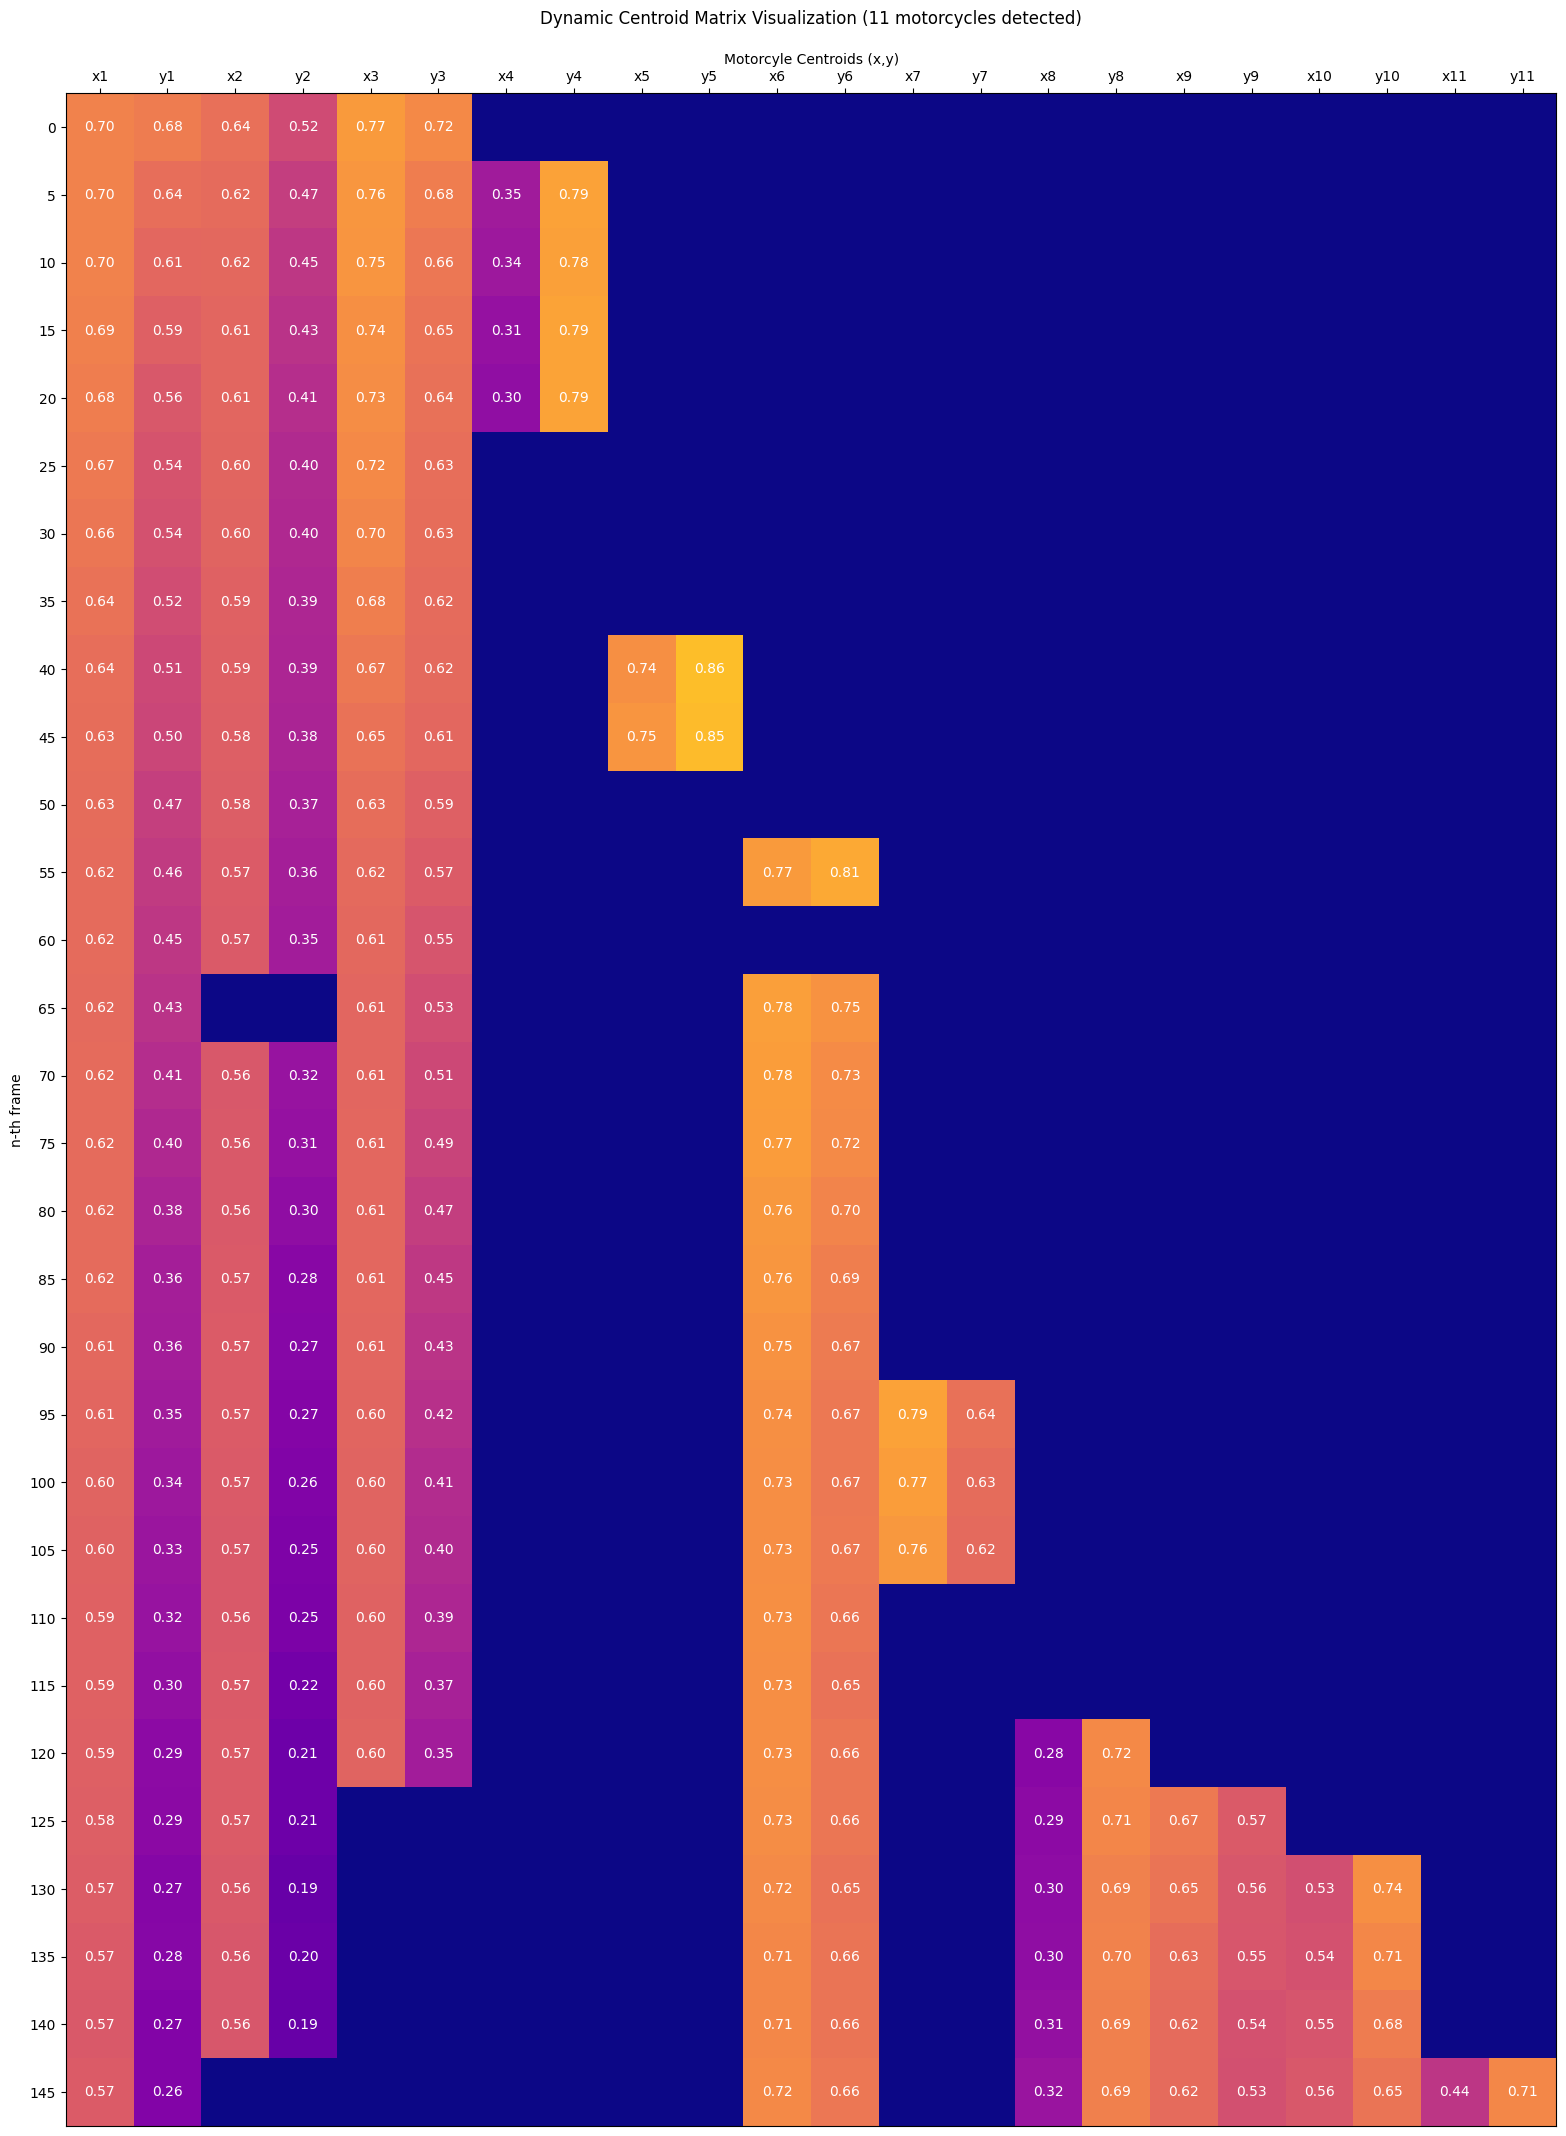

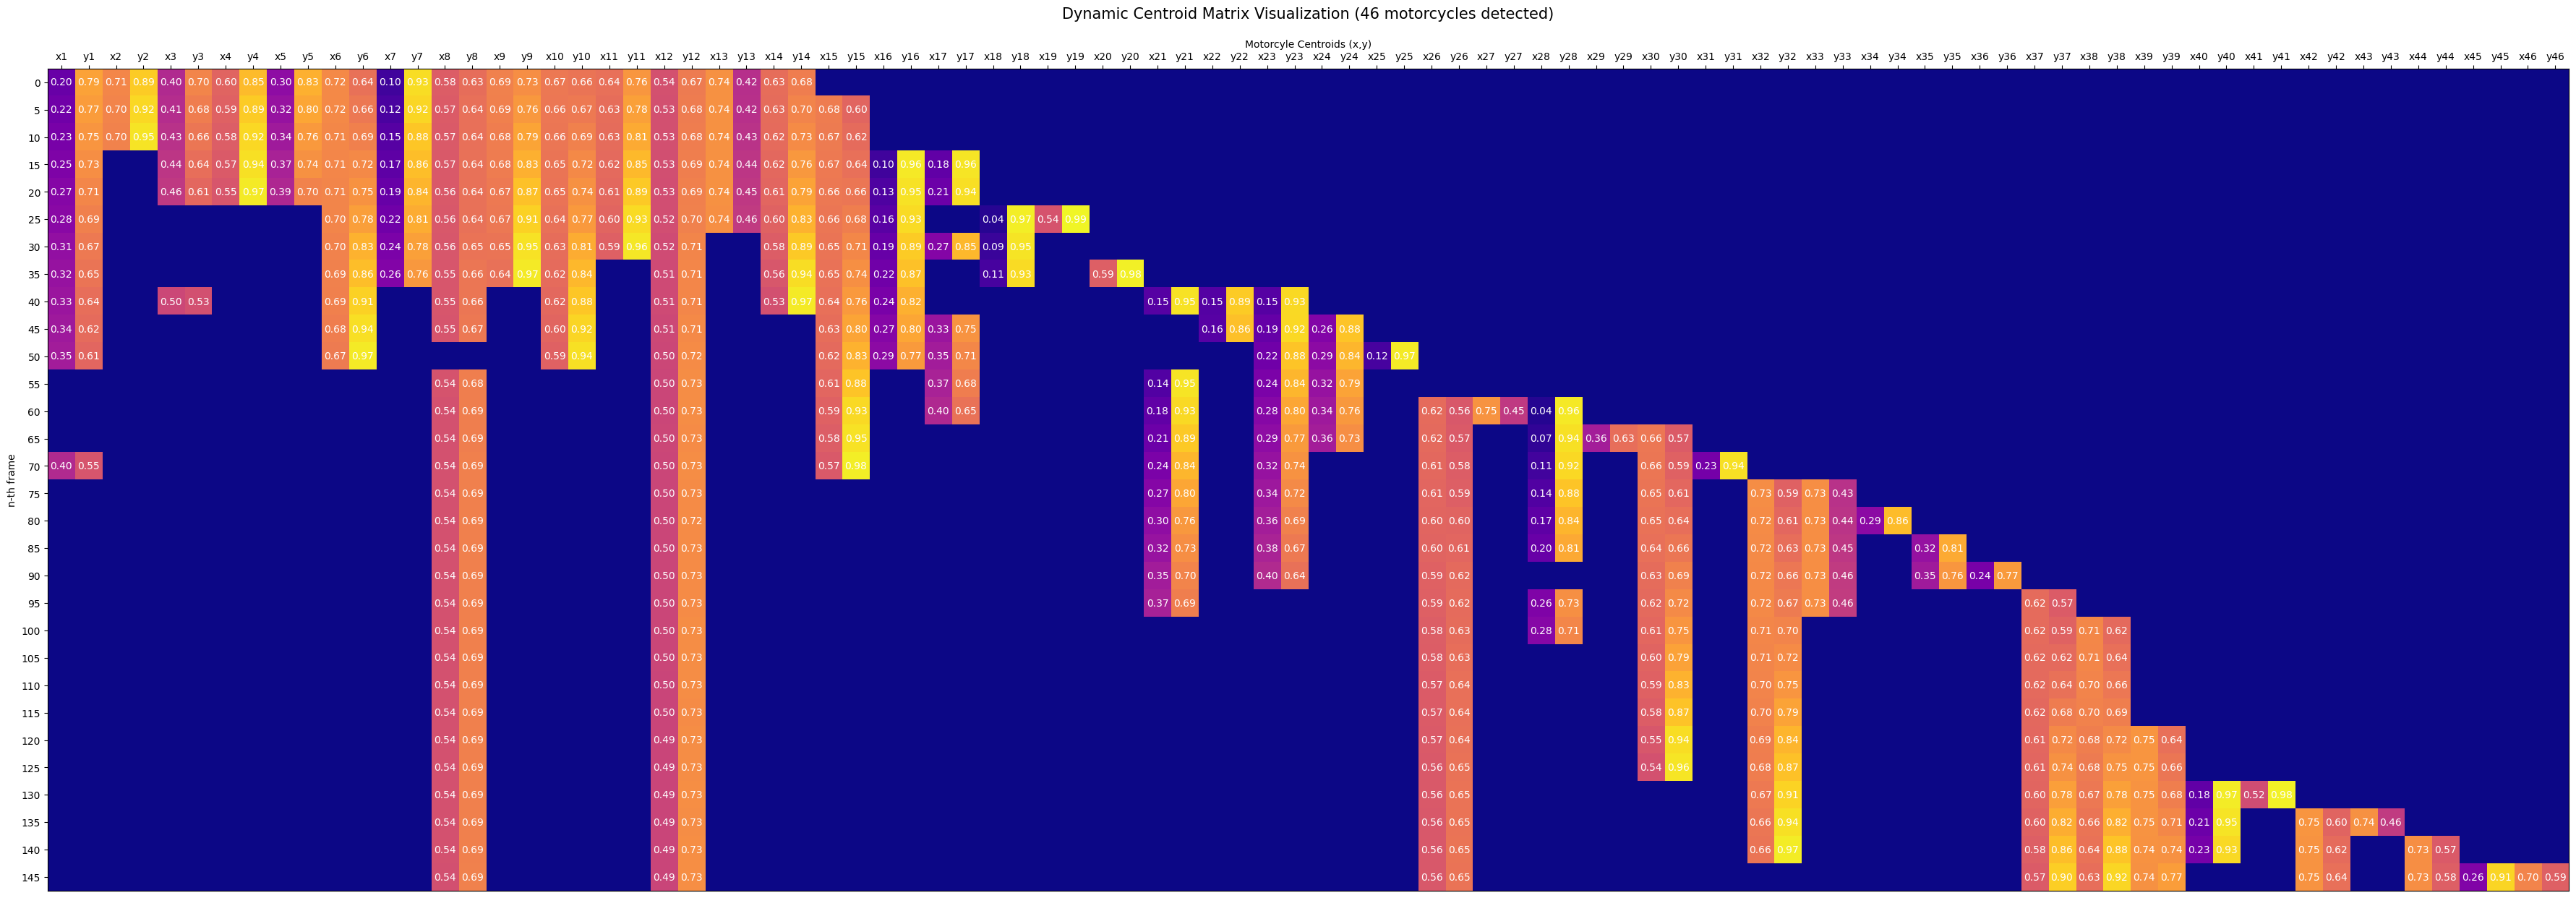

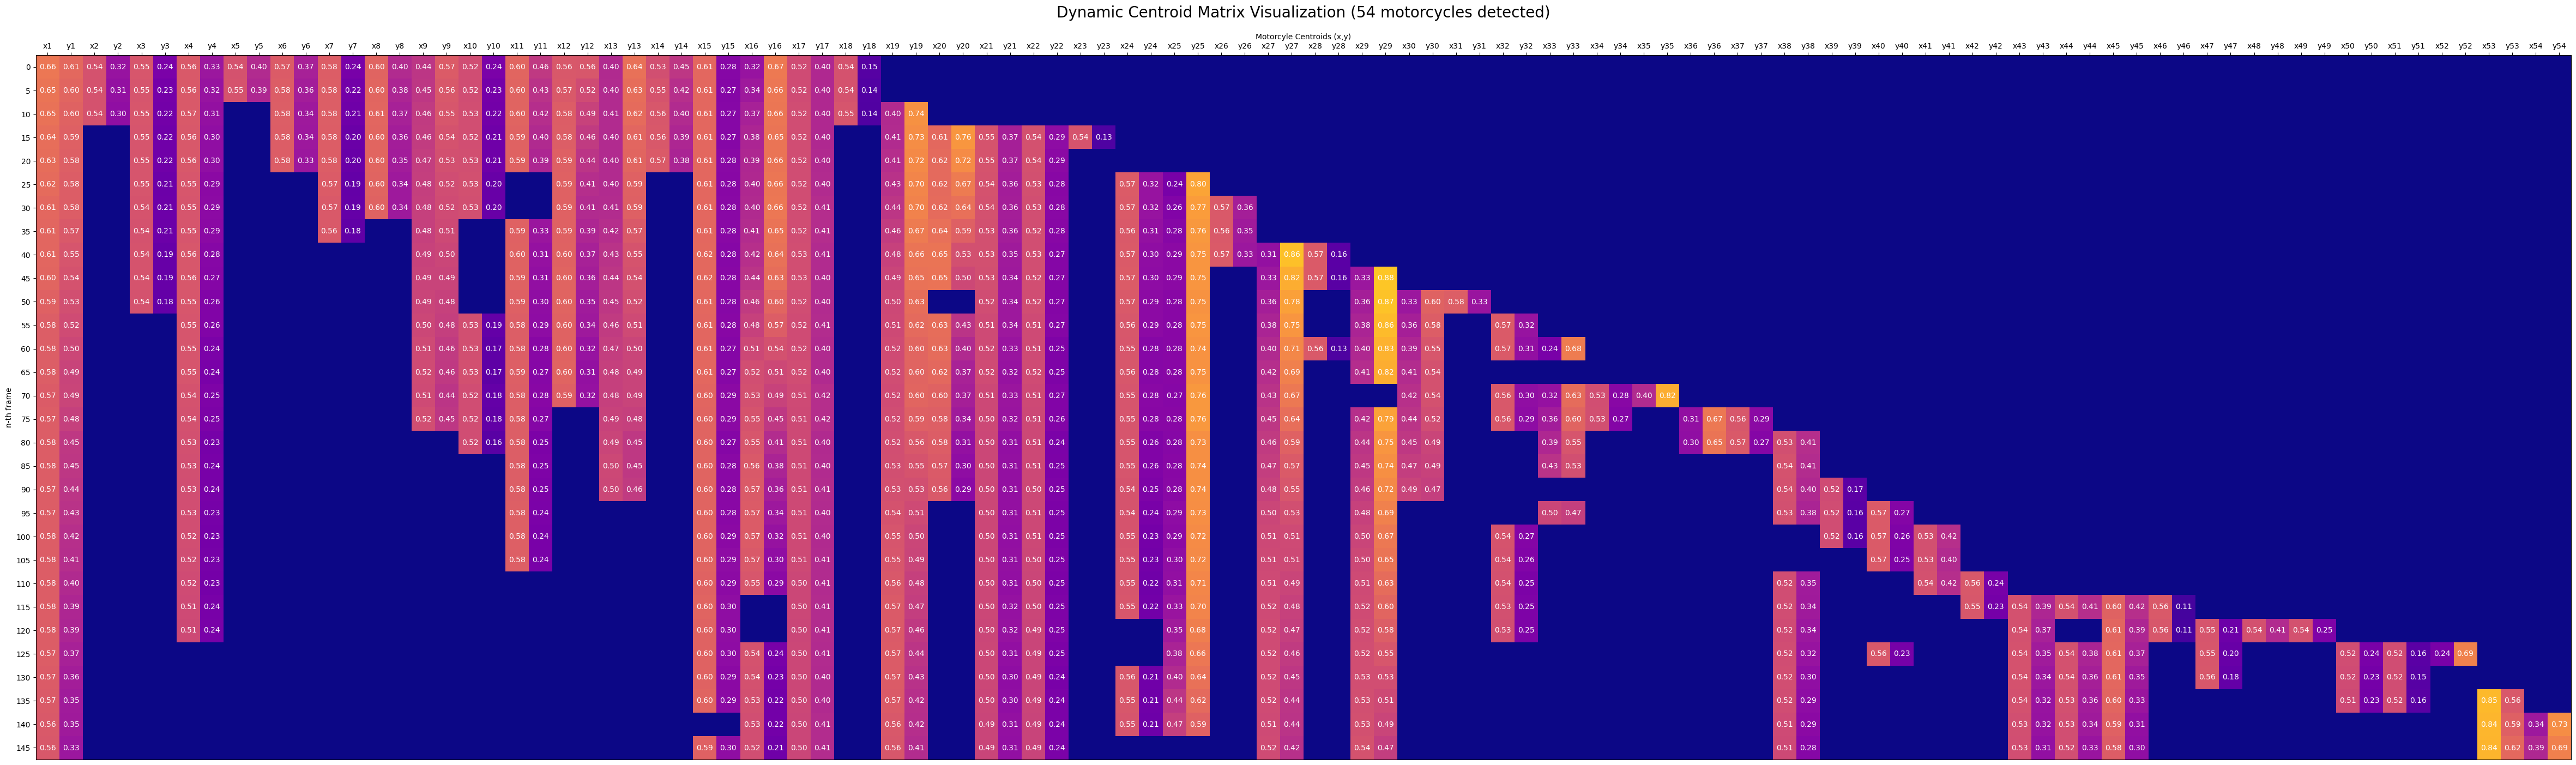

In [44]:
for s in sample:
    m = s[0][0]
    w = m.shape[-1]
    fig = visualize_matrix_details(m)
    for ext in ["svg", "png"]:
        fig.savefig(f"dynamic_matrix_plot_{w}.{ext}", dpi=300 if ext != "svg" else None, bbox_inches='tight')


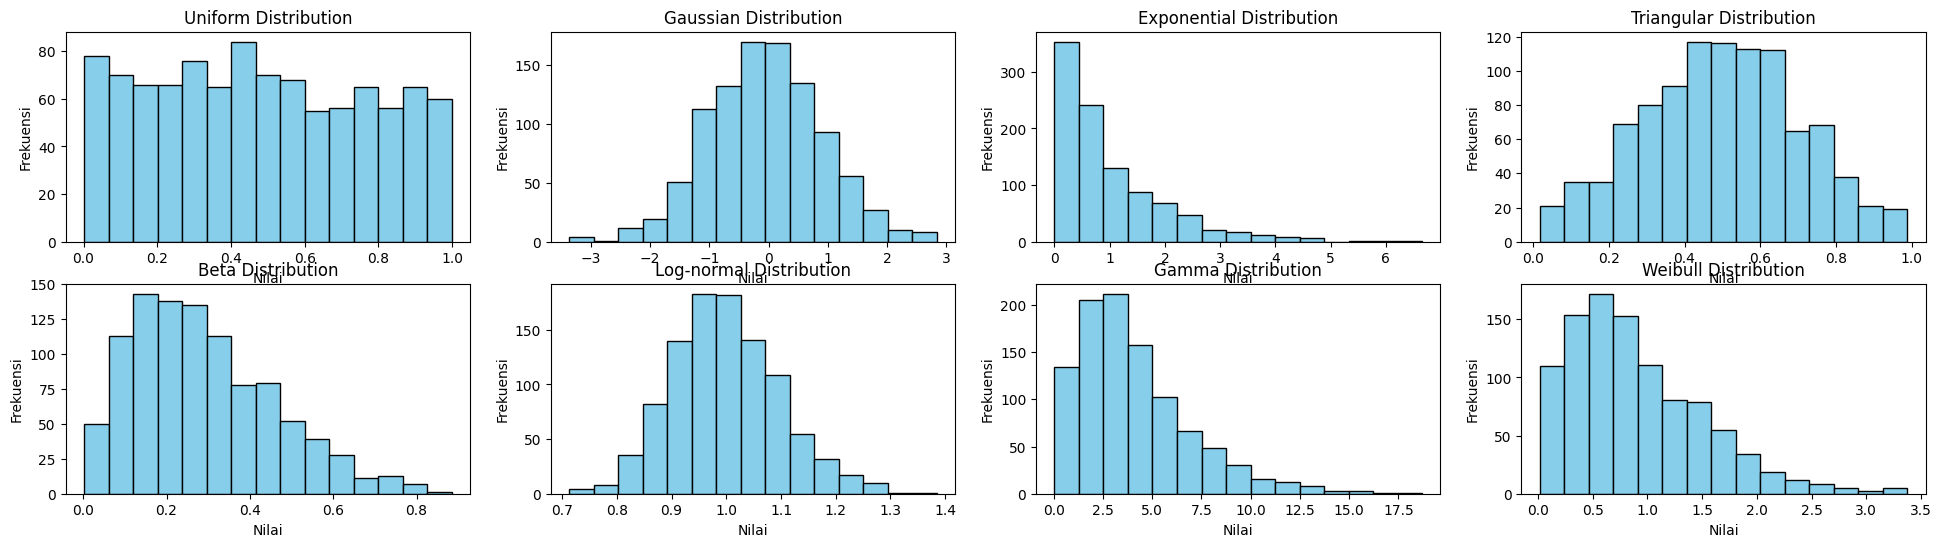

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Contoh data acak
# data_uniform = np.random.rand(1000)
# data_gaussian = np.random.normal(loc=0.0, scale=1.0, size=1000)  # 1000 angka acak dengan distribusi Gaussian
# data_exp = np.random.exponential(scale=1.0, size=1000)  # 1000 angka acak dengan distribusi Eksponensial
data_uniform = [random.random() for _ in range(1000)]
data_gaussian = [random.gauss(0, 1) for _ in range(1000)]
data_exp = [random.expovariate(1.0) for _ in range(1000)]
data_triangular = [random.triangular(0, 1, 0.5) for _ in range(1000)]
data_beta = [random.betavariate(2, 5) for _ in range(1000)]
data_lognormal = [random.lognormvariate(0, 0.1) for _ in range(1000)]
data_gamma = [random.gammavariate(2, 2) for _ in range(1000)]
data_weibull = [random.weibullvariate(1, 1.5) for _ in range(1000)]


fig, axs = plt.subplots(2, 4, figsize=(24, 6))
for i, (data, title) in enumerate(zip([data_uniform, data_gaussian, data_exp, data_triangular, data_beta, data_lognormal, data_gamma, data_weibull],
                                      ["Uniform Distribution", "Gaussian Distribution", "Exponential Distribution",
                                       "Triangular Distribution", "Beta Distribution", "Log-normal Distribution", "Gamma Distribution", "Weibull Distribution"])):
    i = i // 4, i % 4
    axs[i].hist(data, bins=15, color='skyblue', edgecolor='black')
    axs[i].set_title(title)
    axs[i].set_xlabel("Nilai")
    axs[i].set_ylabel("Frekuensi")



In [32]:
axs[0]

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)